# Notebook 1 — What Physical AI Is, and What an Action Really Is

### Course roadmap

**Part I — the data**
1. What Physical AI is & what an action really is · 2. Anatomy of a demonstration

**Part II — simulation from first principles** (`numpy` only)
3. Physics from scratch · 4. The robot model · 5. Control before learning

**Part III — learning policies** (`pytorch`)
6. Behavior cloning · 7. Action chunking & diffusion policies · 8. RL in simulation (SAC)

**Part IV — reality and production**
9. Sim-to-real · 10. `lerobot` end to end

---

### What this notebook does

We do not start with theory. We start by downloading **real data from a real
robot arm** and asking the most basic possible question: *what is an action?*

The answer turns out to be measurable in about five lines of pandas, and it is
the single most useful fact in this entire course. Nearly everything that makes
Physical AI different from the LLM RL you already know follows from it.

By the end you will have:

- a real SO-101 teleoperation dataset loaded in pandas, and know what every column means
- an empirical answer to "what is a robot action" that you derived yourself
- the MDP for this robot written down explicitly, next to the text MDP you already know
- a clear picture of which parts of your agentic RL knowledge transfer and which break

## 1. The function we are building, top down

Strip away every framework and paper and what Physical AI trains is one function:

$$
\pi(\underbrace{\text{camera frames}}_{\text{what it sees}},\ \underbrace{\text{joint positions}}_{\text{where its body is}})\ \longrightarrow\ \underbrace{\text{motor commands}}_{\text{what it does}}
$$

called roughly 30 times a second. That is the whole object. A policy that folds
laundry and a policy that picks items from a warehouse bin are the *same type of
function* with different weights — which is exactly why robot foundation models
work at all.

Three things changed recently enough that this is now learnable by one person:

| | Then | Now |
|---|---|---|
| Hardware | $30,000 industrial arm | **$100–500** 3D-printable SO-101 |
| Data | collect it all yourself | thousands of shared datasets on HuggingFace |
| Method | unclear | imitation learning, then RL fine-tuning |

We are going to use someone else's robot data before you own a robot. That is
the single biggest practical shortcut available in this field, and it is what
this notebook is built on.

## 2. What transfers from your RL work, and what breaks

You already know multi-turn agentic RL. A robot episode is also a multi-turn
POMDP, so a lot transfers. Here is the honest mapping:

| | Agentic RL (you know this) | Physical AI |
|---|---|---|
| Formalism | POMDP | POMDP — **same** |
| One "turn" | a message, ~100 tokens | one control step, **33 ms** |
| Episode | 5–20 turns | **300+ steps** |
| Action | token sequence | 6 continuous numbers |
| Observation | tool output text | camera frames + joint encoders |
| Reward | verifier, 0/1 | hand-designed, or human judgement |
| **Reset to a state?** | **yes** — rerun the prompt | **no** — time moves one way |
| **Branch from a prefix?** | **yes** — resample | **no** — the cup is already knocked over |
| Cost of a bad action | wasted tokens | **broken hardware** |

The two bold rows are the entire difference, and they matter more than they look.

Every branching credit-assignment method you studied — rollout trees, sibling
comparison, VinePPO-style resampling from an intermediate state — needs the
ability to *restore* a state and try something else. In notebook 15 you compared
trajectory GRPO against step-level grouping; both relied on being able to run
many episodes from the same starting point and compare them.

A physical robot cannot do that. There is exactly one timeline. This is why the
field leans on imitation learning instead of exploration, and why so much effort
goes into simulators — a simulator is, more than anything else, *a device that
gives you back the reset button*.

## 3. Get real data from a real robot

We use [`lerobot/svla_so101_pickplace`](https://huggingface.co/datasets/lerobot/svla_so101_pickplace):
50 episodes of a human teleoperating an SO-101 arm to pick an object and place
it, recorded at 30 fps with two cameras.

LeRobot's v3 dataset format splits the data by *type of signal*, which is a
deliberate and sensible choice:

- **Parquet** for low-dimensional, high-frequency signals — joint positions, actions, timestamps
- **MP4** for camera video, which would be absurd to store in a dataframe
- **`meta/info.json`** for the schema: what every column is, its dtype and shape

We read the Parquet directly into pandas. Understanding your data is not an
optional preliminary step that you skip to get to the model — in robot learning
the data *is* the hard part, and a policy can only be as good as the
demonstrations behind it.

In [2]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from huggingface_hub import hf_hub_download

REPO = "lerobot/svla_so101_pickplace"
FPS = 30

# meta/info.json is the schema. Always read this before the data itself.
info = json.load(open(hf_hub_download(REPO, "meta/info.json", repo_type="dataset")))
print(info)

print(f"robot type   : {info['robot_type']}")
print(f"fps          : {info['fps']}  ->  one control step = {1000/info['fps']:.1f} ms")
print(f"episodes     : {info['total_episodes']}")
print(f"frames       : {info['total_frames']}  ({info['total_frames']/info['fps']/60:.1f} minutes of robot time)")
print()
print(f"{'feature':26} {'dtype':8} {'shape':10} names")
print("-" * 92)
for name, f in info["features"].items():
    names = f.get("names")
    if isinstance(names, dict):              # joint names arrive nested under a key like 'motors'
        names = list(names.values())[0]
    shown = ", ".join(names) if isinstance(names, list) else ""
    print(f"{name:26} {f['dtype']:8} {str(f.get('shape')):10} {shown[:46]}")

{'codebase_version': 'v3.0', 'robot_type': 'so100_follower', 'total_episodes': 50, 'total_frames': 11939, 'total_tasks': 1, 'chunks_size': 1000, 'fps': 30, 'splits': {'train': '0:50'}, 'data_path': 'data/chunk-{chunk_index:03d}/file-{file_index:03d}.parquet', 'video_path': 'videos/{video_key}/chunk-{chunk_index:03d}/file-{file_index:03d}.mp4', 'features': {'action': {'dtype': 'float32', 'shape': [6], 'names': ['shoulder_pan.pos', 'shoulder_lift.pos', 'elbow_flex.pos', 'wrist_flex.pos', 'wrist_roll.pos', 'gripper.pos'], 'fps': 30.0}, 'observation.state': {'dtype': 'float32', 'shape': [6], 'names': ['shoulder_pan.pos', 'shoulder_lift.pos', 'elbow_flex.pos', 'wrist_flex.pos', 'wrist_roll.pos', 'gripper.pos'], 'fps': 30.0}, 'observation.images.up': {'dtype': 'video', 'shape': [480, 640, 3], 'names': ['height', 'width', 'channels'], 'info': {'video.height': 480, 'video.width': 640, 'video.codec': 'av1', 'video.pix_fmt': 'yuv420p', 'video.is_depth_map': False, 'video.fps': 30, 'video.channel

Read that table carefully, because it already tells you a great deal.

- **`observation.state`** and **`action`** are both `float32` with shape `[6]`,
  and — this is the important part — **they carry the same six names**:
  `shoulder_pan`, `shoulder_lift`, `elbow_flex`, `wrist_flex`, `wrist_roll`,
  `gripper`.

That is strange if you think of actions the way LLM RL trains you to. There, an
observation and an action are different kinds of object: text coming in, tokens
going out. Here they live in *the same space* with *the same units*.

Hold onto that oddity. Section 5 is going to explain it, and the explanation is
the main lesson of this notebook.

- **`observation.images.up` / `.side`** are `video`, stored as MP4 — this is why
  they will not appear as dataframe columns.
- **`timestamp`, `frame_index`, `episode_index`, `index`, `task_index`** are
  bookkeeping: which episode a row belongs to and where in that episode it sits.

Now the actual data.

In [3]:
parquet_path = hf_hub_download(REPO, "data/chunk-000/file-000.parquet", repo_type="dataset")
df = pd.read_parquet(parquet_path)

print(f"dataframe: {df.shape[0]} rows x {df.shape[1]} columns\n")
print(df.head(4).to_string(max_colwidth=34))
print()
# The two array-valued columns hold python lists; make that explicit.
print("one row of `action`          :", np.asarray(df["action"].iloc[0]).round(2))
print("one row of `observation.state`:", np.asarray(df["observation.state"].iloc[0]).round(2))

dataframe: 11939 rows x 7 columns

                              action                  observation.state  timestamp  frame_index  episode_index  index  task_index
0  [1.9117647, -99.41053, 99.5448...  [1.9560878, -98.74372, 98.9242...   0.000000            0              0      0           0
1  [1.9117647, -99.41053, 99.5448...  [1.9560878, -98.74372, 98.9242...   0.033333            1              0      1           0
2  [1.9117647, -99.41053, 99.5448...  [1.9560878, -98.74372, 98.9242...   0.066667            2              0      2           0
3  [1.9117647, -99.41053, 99.5448...  [1.9560878, -98.74372, 98.9242...   0.100000            3              0      3           0

one row of `action`          : [  1.91 -99.41  99.54  74.84 -48.52   1.62]
one row of `observation.state`: [  1.96 -98.74  98.92  74.82 -51.45   1.41]


In [4]:
df.head()

,action,observation.state,timestamp,frame_index,episode_index,index,task_index
0,"[1.9117647, -99.41053, 99.54483, 74.84063, -48...","[1.9560878, -98.74372, 98.92425, 74.81984, -51...",0.000000,0,0,0,0
1,"[1.9117647, -99.41053, 99.54483, 74.84063, -48...","[1.9560878, -98.74372, 98.92425, 74.81984, -51...",0.033333,1,0,1,0
2,"[1.9117647, -99.41053, 99.54483, 74.84063, -48...","[1.9560878, -98.74372, 98.92425, 74.81984, -51...",0.066667,2,0,2,0
3,"[1.9117647, -99.41053, 99.54483, 74.84063, -48...","[1.9560878, -98.74372, 98.92425, 74.81984, -50...",0.100000,3,0,3,0
4,"[1.9117647, -99.41053, 99.54483, 74.84063, -48...","[1.9560878, -98.74372, 98.92425, 74.81984, -49...",0.133333,4,0,4,0


Note what `pandas` does with the array columns: `action` and
`observation.state` are **object columns holding 6-element arrays**, not six
separate numeric columns. That is normal for robot data and it is the first
thing to fix for analysis, because you cannot take a mean or a correlation
through an object column.

The standard move — and the one every robot-learning codebase makes somewhere —
is `np.stack` to get a clean `(T, 6)` float array per episode.

In [15]:
"""Return (A, S, t) for one episode: actions (T,6), states (T,6), time in seconds (T,)."""
ep = df[df["episode_index"] == 0].sort_values("frame_index")
A = np.stack(ep["action"].values).astype(np.float64)
S = np.stack(ep["observation.state"].values).astype(np.float64)
t = ep["timestamp"].values.astype(np.float64)

In [19]:
pd.DataFrame(S)

,0,1,2,3,4,5
0,1.956088,-98.743721,98.924248,74.819839,-51.452991,1.409396
1,1.956088,-98.743721,98.924248,74.819839,-51.452991,1.409396
2,1.956088,-98.743721,98.924248,74.819839,-51.306473,1.409396
3,1.956088,-98.743721,98.924248,74.819839,-50.525032,1.409396
4,1.956088,-98.743721,98.924248,74.819839,-49.841270,1.409396
...,...,...,...,...,...,...
298,4.510978,-98.827469,98.834602,74.735054,-59.120880,1.208054
299,4.510978,-98.827469,98.834602,74.735054,-59.120880,1.208054
300,4.510978,-98.827469,98.834602,74.735054,-59.120880,1.208054
301,4.510978,-98.827469,98.834602,74.735054,-59.120880,1.208054


In [6]:
JOINTS = ["shoulder_pan", "shoulder_lift", "elbow_flex", "wrist_flex", "wrist_roll", "gripper"]

def episode(ep_index):
    """Return (A, S, t) for one episode: actions (T,6), states (T,6), time in seconds (T,)."""
    ep = df[df["episode_index"] == ep_index].sort_values("frame_index")
    A = np.stack(ep["action"].values).astype(np.float64)
    S = np.stack(ep["observation.state"].values).astype(np.float64)
    t = ep["timestamp"].values.astype(np.float64)
    return A, S, t

In [8]:
df["episode_index"].value_counts()

episode_index
41    306
0     303
46    303
40    293
30    288
43    281
31    272
48    272
49    271
32    270
1     266
42    263
35    262
44    261
47    259
38    256
36    254
45    250
17    243
20    243
33    239
39    238
22    237
5     231
13    231
2     230
37    227
8     226
15    226
6     224
21    224
28    224
14    223
24    223
29    223
25    220
10    216
4     215
18    214
23    211
12    210
19    210
34    207
9     204
7     203
27    203
11    201
16    201
26    199
3     183
Name: count, dtype: int64

In [ ]:


# How long is an episode? This is our horizon, and it is nothing like a text episode.
lengths = df.groupby("episode_index").size()
print(f"episode length: min {lengths.min()}, median {int(lengths.median())}, max {lengths.max()} frames")
print(f"             = {lengths.min()/FPS:.1f}s to {lengths.max()/FPS:.1f}s of wall-clock time")
print()
print(f"So one episode is ~{int(lengths.median())} decisions.")
print(f"In notebook 15 a long-horizon agentic task meant H = 16 turns. Here the horizon is ~{int(lengths.median()//16)}x longer.")

episode length: min 183, median 230, max 306 frames
             = 6.1s to 10.2s of wall-clock time

So one episode is ~230 decisions.
In notebook 15 a long-horizon agentic task meant H = 16 turns. Here the horizon is ~14x longer.


That horizon number is worth sitting with. In your agentic RL work, 16 turns
counted as a *long* horizon and credit assignment was already hard there. A
single 10-second robot episode involves roughly 300 sequential decisions, and a
real task can run for minutes.

If you tried to assign credit across 300 steps from a single terminal reward,
with no ability to reset and branch, you would be attempting something strictly
harder than anything in the previous course. **This is the quantitative reason
imitation learning dominates physical AI.** With demonstrations you get a
supervision signal at every one of those 300 steps, instead of one bit at the end.

## 4. The central experiment: what *is* an action?

Back to the oddity from section 3. `action` and `observation.state` have the
same six names and the same units. Why?

There are three candidate stories, and they are genuinely different physics:

1. **Action is a torque / force.** The policy commands effort, and position is a
   downstream consequence. This is what most RL textbook environments do, and
   what `Pendulum-v1` does.
2. **Action is the next position, reached instantly.** The policy commands
   "be here now" and the arm teleports. Physically impossible, but it is what a
   naive reading of "same units" might suggest.
3. **Action is a position *target*, and the physical arm chases it with lag.**
   The policy says "go here"; a motor controller underneath pushes the joint
   toward that target; mass and friction mean it arrives late.

These make *different, testable predictions* about the data. If (3) is true,
then `action[t]` should look like `observation.state[t + k]` for some positive
lag $k$ — the arm reaches at time $t+k$ the place it was told to go at time $t$.

So let us just measure it. Sweep $k$, and for each one compute the mean absolute
difference between the action and the state $k$ frames later. The lag that
minimises that error is our answer.

In [9]:
A, S, t = episode(0)
print(f"episode 0: {len(A)} frames = {len(A)/FPS:.1f} seconds\n")

print("Hypothesis: action[t] is a position target that the arm reaches at state[t+k].")
print("Sweep the lag k and find which one explains the data best.\n")
print(f"{'lag k':>6} {'ms':>6} {'mean |action[t] - state[t+k]|':>32}")
print("-" * 48)
errors = []
for k in range(0, 9):
    err = np.abs(A[:len(A) - k] - S[k:]).mean()
    errors.append(err)
    print(f"{k:>6} {k*1000/FPS:>6.0f} {err:>32.3f}")

best_k = int(np.argmin(errors))
print()
print(f"best lag = {best_k} frames = {best_k*1000/FPS:.0f} ms")
print(f"error at lag 0 : {errors[0]:.3f}")
print(f"error at lag {best_k} : {errors[best_k]:.3f}   ({100*(1-errors[best_k]/errors[0]):.0f}% lower)")

episode 0: 303 frames = 10.1 seconds

Hypothesis: action[t] is a position target that the arm reaches at state[t+k].
Sweep the lag k and find which one explains the data best.

 lag k     ms    mean |action[t] - state[t+k]|
------------------------------------------------
     0      0                            2.109
     1     33                            1.725
     2     67                            1.341
     3    100                            0.971
     4    133                            0.770
     5    167                            1.018
     6    200                            1.361
     7    233                            1.738
     8    267                            2.124

best lag = 4 frames = 133 ms
error at lag 0 : 2.109
error at lag 4 : 0.770   (63% lower)


There it is, and it is not subtle.

The error falls as $k$ increases, bottoms out, then climbs again. That shape is
the signature of a real physical delay: too early and the arm has not arrived
yet, too late and it has already moved on to the next target.

Hypothesis (3) wins. Let us confirm it per joint with a correlation, which is
scale-free and so lets us compare a shoulder against a gripper.

In [10]:
print(f"correlation between action[t] and state[t+{best_k}], per joint:\n")
print(f"{'joint':16} {'corr @ lag 0':>13} {f'corr @ lag {best_k}':>14} {'action range':>24}")
print("-" * 72)
for i, j in enumerate(JOINTS):
    c0 = np.corrcoef(A[:, i], S[:, i])[0, 1]
    ck = np.corrcoef(A[:len(A) - best_k, i], S[best_k:, i])[0, 1]
    print(f"{j:16} {c0:>13.4f} {ck:>14.4f} {f'[{A[:, i].min():7.1f}, {A[:, i].max():7.1f}]':>24}")

print()
print("Near-perfect correlation at the best lag. The action is the target; the state is the arrival.")

correlation between action[t] and state[t+4], per joint:

joint             corr @ lag 0   corr @ lag 4             action range
------------------------------------------------------------------------
shoulder_pan            0.9847         1.0000       [    1.7,    85.7]
shoulder_lift           0.9906         0.9999       [ -100.0,     2.1]
elbow_flex              0.9902         0.9994       [   29.9,    99.5]
wrist_flex              0.9709         0.9996       [   46.1,    86.5]
wrist_roll              0.9761         0.9996       [  -59.3,   -34.1]
gripper                 0.8999         0.9554       [    0.1,    20.7]

Near-perfect correlation at the best lag. The action is the target; the state is the arrival.


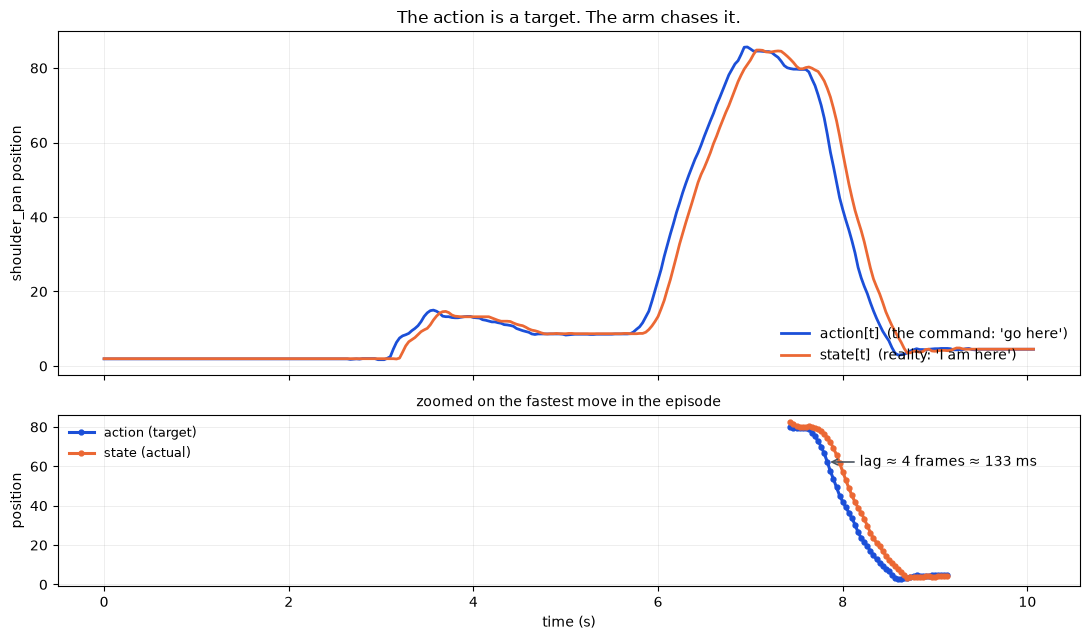

In [11]:
# See it directly. One joint, one episode: the command and the response.
fig, axes = plt.subplots(2, 1, figsize=(11, 6.5), sharex=True,
                         gridspec_kw={"height_ratios": [2, 1]})

i = JOINTS.index("shoulder_pan")
ax = axes[0]
ax.plot(t, A[:, i], lw=2.0, label="action[t]  (the command: 'go here')", color="#1b4fd8")
ax.plot(t, S[:, i], lw=2.0, label="state[t]  (reality: 'I am here')", color="#eb6834")
ax.set_ylabel("shoulder_pan position")
ax.set_title("The action is a target. The arm chases it.", fontsize=12)
ax.legend(frameon=False, loc="lower right")
ax.grid(alpha=0.25, lw=0.6)

# Zoom on a fast move, where the lag is visible to the eye.
jump = int(np.argmax(np.abs(np.diff(A[:, i]))))
lo, hi = max(0, jump - 12), min(len(t), jump + 40)
ax = axes[1]
ax.plot(t[lo:hi], A[lo:hi, i], lw=2.2, marker="o", ms=3.5, label="action (target)", color="#1b4fd8")
ax.plot(t[lo:hi], S[lo:hi, i], lw=2.2, marker="o", ms=3.5, label="state (actual)", color="#eb6834")
ax.annotate(f"lag ≈ {best_k} frames ≈ {best_k*1000/FPS:.0f} ms",
            xy=(t[jump], A[jump, i]), xytext=(t[jump] + 0.35, A[jump, i]),
            fontsize=10, va="center",
            arrowprops=dict(arrowstyle="->", lw=1.2, color="#4b5560"))
ax.set_xlabel("time (s)"); ax.set_ylabel("position")
ax.set_title("zoomed on the fastest move in the episode", fontsize=10)
ax.legend(frameon=False, loc="best", fontsize=9)
ax.grid(alpha=0.25, lw=0.6)
plt.tight_layout(); plt.show()

The bottom panel is the whole notebook in one picture. The blue line steps to a
new value; the orange line takes a few frames to get there, overshooting or
easing in depending on the joint. **The command and the response are different
curves, separated in time.**

Let us check this is not a fluke of episode 0.

In [12]:
print("best lag per episode, across the whole dataset:\n")
best_lags = []
for e in sorted(df["episode_index"].unique()):
    Ae, Se, _ = episode(e)
    if len(Ae) < 20:
        continue
    errs = [np.abs(Ae[:len(Ae) - k] - Se[k:]).mean() for k in range(9)]
    best_lags.append(int(np.argmin(errs)))

best_lags = np.array(best_lags)
vals, counts = np.unique(best_lags, return_counts=True)
for v, c in zip(vals, counts):
    bar = "#" * int(40 * c / counts.max())
    print(f"  lag {v} ({v*1000/FPS:>3.0f} ms): {bar} {c} episodes")
print(f"\nmedian best lag across {len(best_lags)} episodes: {int(np.median(best_lags))} frames "
      f"= {np.median(best_lags)*1000/FPS:.0f} ms")

best lag per episode, across the whole dataset:

  lag 4 (133 ms): ######################################## 50 episodes

median best lag across 50 episodes: 4 frames = 133 ms


Consistent across the dataset. This is a property of **the robot**, not of any
one episode: a real, repeatable actuation delay of roughly 100–130 ms baked into
the hardware.

### The result, stated plainly

> A robot action in this dataset is a **position setpoint**. The policy does not
> move the joint; it declares where the joint should be. Underneath, a motor
> controller you did not write pushes the joint toward that setpoint, and mass,
> friction and gearing mean it arrives about **4 frames (130 ms) later**.

You now know what the numbers in the `action` column mean, which is more than
you can get from reading a paper about this dataset.

## 5. Why this one fact explains most of the course

This is the part worth internalising. Four apparently separate topics in
physical AI are all consequences of the measurement you just made.

**1. Actions have momentum, so mistakes are not free.**
In LLM RL a bad token costs you a bad token. Here, by the time the policy
observes the consequence of a command, the arm has already been moving toward it
for 130 ms. You cannot recall it. This is the physical root of the
"no branching, no reset" row in the section 2 table — irreversibility is not a
policy choice, it is inertia.

**2. Control frequency is a real design parameter.**
At 30 fps each step is 33 ms and the lag is ~4 steps. Run the policy at 5 Hz
instead and the lag is under one step — the arm arrives before you next look,
and your MDP is nearly deterministic but sluggish. Run at 200 Hz and the lag is
26 steps, so the state barely changes between decisions and the credit
assignment problem gets dramatically worse. **The same robot gives you a
different MDP depending on how fast you ask it questions.**

**3. Latency *is* the sim-to-real gap, in large part.**
A default simulator applies your command essentially instantly. Deploy a policy
trained that way onto this arm and every command lands 130 ms late. The policy
is now closing a feedback loop on stale information, which is a classic recipe
for oscillation. In notebook 9 we inject exactly the lag we just measured and
watch what it does to a trained policy — and that is why measuring it here, in
notebook 1, is worth the effort.

**4. Action chunking stops being a mystery.**
Modern policies (π0, diffusion policy, GR00T) do not predict one action. They
predict a *chunk* — the next ~16 actions at once. Given what you just measured,
that is the obvious engineering response: if your command takes 4 steps to land
anyway, predicting one step at a time wastes the interval and invites jitter as
consecutive independent predictions disagree. Committing to a short plan is both
smoother and cheaper. Notebook 7 builds this.

If you remember one thing from this notebook, make it this: **the action is a
target, and reality lags.** It is the "spring" of physical AI — a single
mechanical picture that makes a dozen separate design decisions feel inevitable
instead of arbitrary.

## 6. Writing down the MDP, explicitly

You have done this many times for text. Let us do it for atoms, side by side, so
the comparison is concrete rather than vibes.

For this robot:

| Symbol | For the SO-101 pick-and-place task |
|---|---|
| $\mathcal{S}$ | 6 joint positions, plus object pose — **which we cannot observe**, hence POMDP |
| $\mathcal{O}$ | 6 joint encoder readings $+$ two $480\times640\times3$ camera frames |
| $\mathcal{A}$ | $\mathbb{R}^6$ — continuous joint *targets*, not torques |
| $P(s'\mid s,a)$ | **the laws of physics** — not a lookup table, not a language model |
| $R$ | not in this dataset at all. Teleoperation has no reward |
| $\gamma$ | ~0.99 at 30 fps: a horizon of 300 steps needs $\gamma$ close to 1 |
| $H$ | ~230 steps (183–306 in this dataset) |

Two rows deserve comment.

**$P$ is physics.** In your text MDPs the transition function was either a small
matrix you wrote (notebook 1 of the RL course) or a language model. Here it is
the actual dynamics of a physical object. You cannot write it down, you cannot
query it in closed form, and you cannot differentiate through it. What you *can*
do is approximate it — and a simulator is precisely an approximation of $P$.
That is why Part II of this course builds one from scratch.

**There is no reward.** This is not an oversight in the dataset; teleoperated
demonstrations simply have no reward signal. A human moved the arm and it worked.
That absence is the fork in the road for the whole field:

- **Imitation learning** needs no reward. Treat the human's action as the label
  and do supervised learning. This is notebook 6.
- **RL** needs a reward, which someone must design — and designing one for
  "did it pick up the cup" is genuinely hard and easy to hack. Your notebook 15
  work on potential-based shaping versus hackable process rewards applies
  directly.

Let us confirm the reward really is absent, and then look at a dataset that has one.

In [13]:
print("reward-like columns in the SO-101 teleop data:")
print("  ", [c for c in df.columns if any(k in c for k in ("reward", "done", "success"))] or "NONE — as expected")
print()

# pusht is the contrast case: same format, but recorded from an MDP with a reward.
pusht_info = json.load(open(hf_hub_download("lerobot/pusht", "meta/info.json", repo_type="dataset")))
pusht = pd.read_parquet(hf_hub_download("lerobot/pusht", "data/chunk-000/file-000.parquet", repo_type="dataset"))

print(f"lerobot/pusht: {pusht_info['total_episodes']} episodes, {pusht_info['total_frames']} frames, "
      f"{pusht_info['fps']} fps, action dim {pusht_info['features']['action']['shape']}")
print("  reward-like columns:", [c for c in pusht.columns if any(k in c for k in ("reward", "done", "success"))])
print()
print(pusht[["episode_index", "frame_index", "observation.state", "action",
             "next.reward", "next.done", "next.success"]].head(3).to_string(max_colwidth=22))
print()
ep0 = pusht[pusht.episode_index == 0]
print(f"episode 0: {len(ep0)} frames, reward from {ep0['next.reward'].min():.3f} to {ep0['next.reward'].max():.3f}, "
      f"success reached: {bool(ep0['next.success'].any())}")
print("\n`next.reward` is dense and shaped (it grows as the T-block approaches the goal pose),")
print("which is a hand-designed signal — exactly the kind of shaping you analysed in notebook 15.")

reward-like columns in the SO-101 teleop data:
   NONE — as expected

lerobot/pusht: 206 episodes, 25650 frames, 10 fps, action dim [2]
  reward-like columns: ['next.reward', 'next.done', 'next.success']

   episode_index  frame_index      observation.state         action  next.reward  next.done  next.success
0              0            0          [222.0, 97.0]  [233.0, 71.0]     0.190297      False         False
1              0            1   [225.2524, 89.31253]  [229.0, 83.0]     0.190297      False         False
2              0            2  [227.59233, 84.53438]  [229.0, 86.0]     0.190297      False         False

episode 0: 161 frames, reward from 0.174 to 0.873, success reached: False

`next.reward` is dense and shaped (it grows as the T-block approaches the goal pose),
which is a hand-designed signal — exactly the kind of shaping you analysed in notebook 15.


So we have both halves of the field in two datasets of the same format:

- **`svla_so101_pickplace`** — real hardware, no reward. The imitation learning track.
- **`pusht`** — simulated planar pushing, dense shaped reward, `done` and
  `success` flags. A genuine MDP you can run RL on.

We will use both: the SO-101 data for notebooks 2, 6 and 7, and `pusht` when we
want a reward to optimise.

## 7. One more look: what does a demonstration actually contain?

Before closing, a quick look at the *shape* of the behaviour, because it sets up
notebook 2. A pick-and-place is not homogeneous — it has phases, and the gripper
tells you where they are.

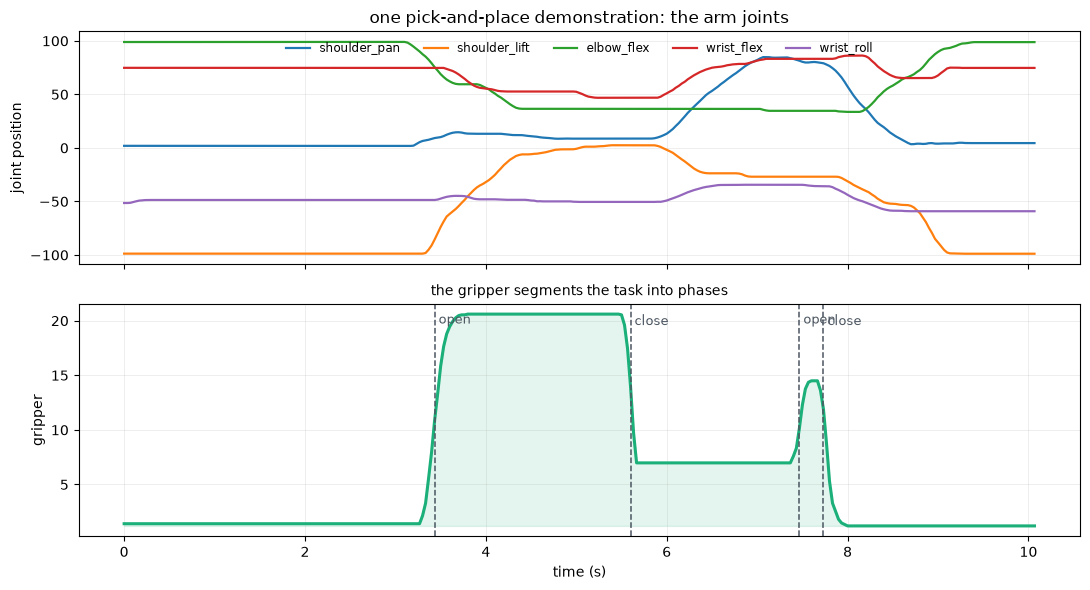

gripper transitions at t = [3.43, 5.6, 7.47, 7.73] s
reach -> grasp -> transport -> release -> retreat, recoverable from one column.


In [14]:
A, S, t = episode(0)
g = JOINTS.index("gripper")

fig, axes = plt.subplots(2, 1, figsize=(11, 6), sharex=True)

ax = axes[0]
for i, j in enumerate(JOINTS):
    if j == "gripper":
        continue
    ax.plot(t, S[:, i], lw=1.6, label=j)
ax.set_ylabel("joint position")
ax.set_title("one pick-and-place demonstration: the arm joints", fontsize=12)
ax.legend(frameon=False, ncol=5, fontsize=8.5, loc="upper center")
ax.grid(alpha=0.25, lw=0.6)

ax = axes[1]
ax.plot(t, S[:, g], lw=2.2, color="#1baf7a")
ax.fill_between(t, S[:, g].min(), S[:, g], alpha=0.12, color="#1baf7a")
# A simple threshold splits "open" from "closed" and marks the grasp and release.
thresh = (S[:, g].max() + S[:, g].min()) / 2
closed = S[:, g] < thresh
switches = np.where(np.diff(closed.astype(int)) != 0)[0]
for sw in switches:
    ax.axvline(t[sw], color="#4b5560", ls="--", lw=1.1)
    ax.text(t[sw], S[:, g].max(), " close" if closed[sw + 1] else " open",
            fontsize=9, va="top", color="#4b5560")
ax.set_xlabel("time (s)"); ax.set_ylabel("gripper")
ax.set_title("the gripper segments the task into phases", fontsize=10)
ax.grid(alpha=0.25, lw=0.6)
plt.tight_layout(); plt.show()

print(f"gripper transitions at t = {[round(float(t[s]), 2) for s in switches]} s")
print("reach -> grasp -> transport -> release -> retreat, recoverable from one column.")

The gripper channel alone recovers the task structure: reach, grasp, transport,
release, retreat. Nothing hand-labelled — it falls out of a threshold.

This matters for two reasons we will come back to. First, those phase boundaries
are where demonstrations disagree most between episodes, and disagreement in the
data is what makes a behavior-cloning policy hesitate. Second, the grasp moment
is a **contact event** — the instant the robot stops moving freely through air
and starts pushing against a thing. Contact is where simulators are least
accurate and where learned policies most often fail, which is the whole subject
of notebook 5.

## 8. What you now know, and what is next

**Established empirically in this notebook:**

1. A robot action in this dataset is a **position target**, not a force, and the
   arm reaches it about **4 frames (130 ms) late**. You measured this yourself
   from 50 episodes.
2. An episode is **~230 sequential decisions** (183-306 here), roughly 14x the
   horizon of the long-horizon agentic tasks you worked on.
3. Teleoperated data has **no reward**, which is why imitation learning rather
   than RL is the default. `pusht` shows the contrast case.
4. The transition function is **physics** — not writable, not differentiable.
   A simulator is an approximation of it, which is why we build one next.

**What transfers from your RL work:** the POMDP formalism, policy gradients,
advantage estimation, reward-hacking instincts, long-horizon credit assignment.

**What breaks:** anything that needs a reset or a branch. There is one timeline.

---

### Next: notebook 2 — Anatomy of a Demonstration

We stay in pandas and go deeper into this dataset: velocities and what they say
about smoothness, where episodes disagree with each other, how to normalise the
data for training, and how to spot a bad demonstration before it poisons your
policy. The goal is to be able to pick up any robot dataset on HuggingFace and
know within ten minutes whether it is worth training on.

### Exercises

1. **Is the lag the same for every joint?** Run the lag sweep per joint rather
   than averaged. The gripper has the lowest correlation in our table — does it
   also have a different lag, and can you explain why from its mechanics?
2. **Velocity.** Compute `np.diff(S, axis=0) * FPS` to get joint velocities in
   units/second. Which joint moves fastest? Does the lag correlate with how fast
   a joint is being asked to move?
3. **Re-run section 4 on `pusht`.** It has 2-D actions and a different fps. Is
   its action also a position target with lag, or something else? (Look at the
   action ranges before you guess.)
4. **The 5 Hz thought experiment.** If you subsample this dataset to 5 Hz, the
   lag becomes under one step. Write down what that does to the MDP — and what
   you lose by throwing away 25 of every 30 frames.